In [2]:
# Churn prediction is about identifying readers who are likely
# to stop visiting a news platform before they actually leave.
# This gives publishers a chance to re-engage them in time.
# We simulate realistic reader behaviour data and train
# a model to predict churn — mirroring Upscore's Convert product.

print("Starting churn prediction notebook...")

Starting churn prediction notebook...


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.sklearn
import os

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, f1_score,
    roc_auc_score, classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")
print("Libraries imported!")

Libraries imported!


In [4]:
# We simulate reader behaviour because we don't have
# real subscription data. The features we create are
# realistic and based on how news platforms actually
# measure reader engagement. In a real project at
# Upscore this data would come from their analytics platform.

np.random.seed(42)
n_readers = 5000

# Each reader gets a unique ID
reader_ids = [f"reader_{i}" for i in range(n_readers)]

# How many articles they read per week on average
articles_per_week = np.random.poisson(lam=7, size=n_readers)

# Average time spent per session in minutes
avg_session_minutes = np.random.exponential(scale=8, size=n_readers)

# How many days since their last visit
days_since_last_visit = np.random.exponential(scale=5, size=n_readers)

# How many weeks they have been a subscriber
weeks_subscribed = np.random.randint(1, 104, size=n_readers)

# How many different topic categories they read
topic_diversity = np.random.randint(1, 5, size=n_readers)

# How many newsletter emails they opened last month
newsletter_opens = np.random.poisson(lam=3, size=n_readers)

# Whether they use the mobile app (1) or not (0)
uses_app = np.random.binomial(1, 0.4, size=n_readers)

# Churn label — readers with low engagement are more likely to churn
# We use a formula that reflects real churn drivers
churn_score = (
    - 0.3 * articles_per_week
    - 0.2 * avg_session_minutes
    + 0.4 * days_since_last_visit
    - 0.1 * weeks_subscribed
    - 0.1 * newsletter_opens
    + np.random.normal(0, 1, size=n_readers)
)

# Convert score to binary churn label
# roughly 30% churn rate which is realistic
churn_threshold = np.percentile(churn_score, 70)
churn = (churn_score > churn_threshold).astype(int)

df_readers = pd.DataFrame({
    "reader_id": reader_ids,
    "articles_per_week": articles_per_week,
    "avg_session_minutes": avg_session_minutes.round(1),
    "days_since_last_visit": days_since_last_visit.round(1),
    "weeks_subscribed": weeks_subscribed,
    "topic_diversity": topic_diversity,
    "newsletter_opens": newsletter_opens,
    "uses_app": uses_app,
    "churn": churn
})

print(f"Created {len(df_readers):,} reader profiles")
print(f"Churn rate: {churn.mean():.1%}")
print()
display(df_readers.head())

Created 5,000 reader profiles
Churn rate: 30.0%



,reader_id,articles_per_week,avg_session_minutes,days_since_last_visit,weeks_subscribed,topic_diversity,newsletter_opens,uses_app,churn
0,reader_0,6,3.0,3.1,21,3,1,0,1
1,reader_1,7,1.0,11.8,5,3,2,1,1
2,reader_2,6,0.5,3.1,36,4,1,0,1
3,reader_3,7,1.0,0.5,91,2,5,0,0
4,reader_4,7,16.7,4.5,7,2,4,0,0


/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79948/1363294589.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79948/1363294589.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels(["Stayed", "Churned"])
/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79948/1363294589.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79948/1363294589.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_

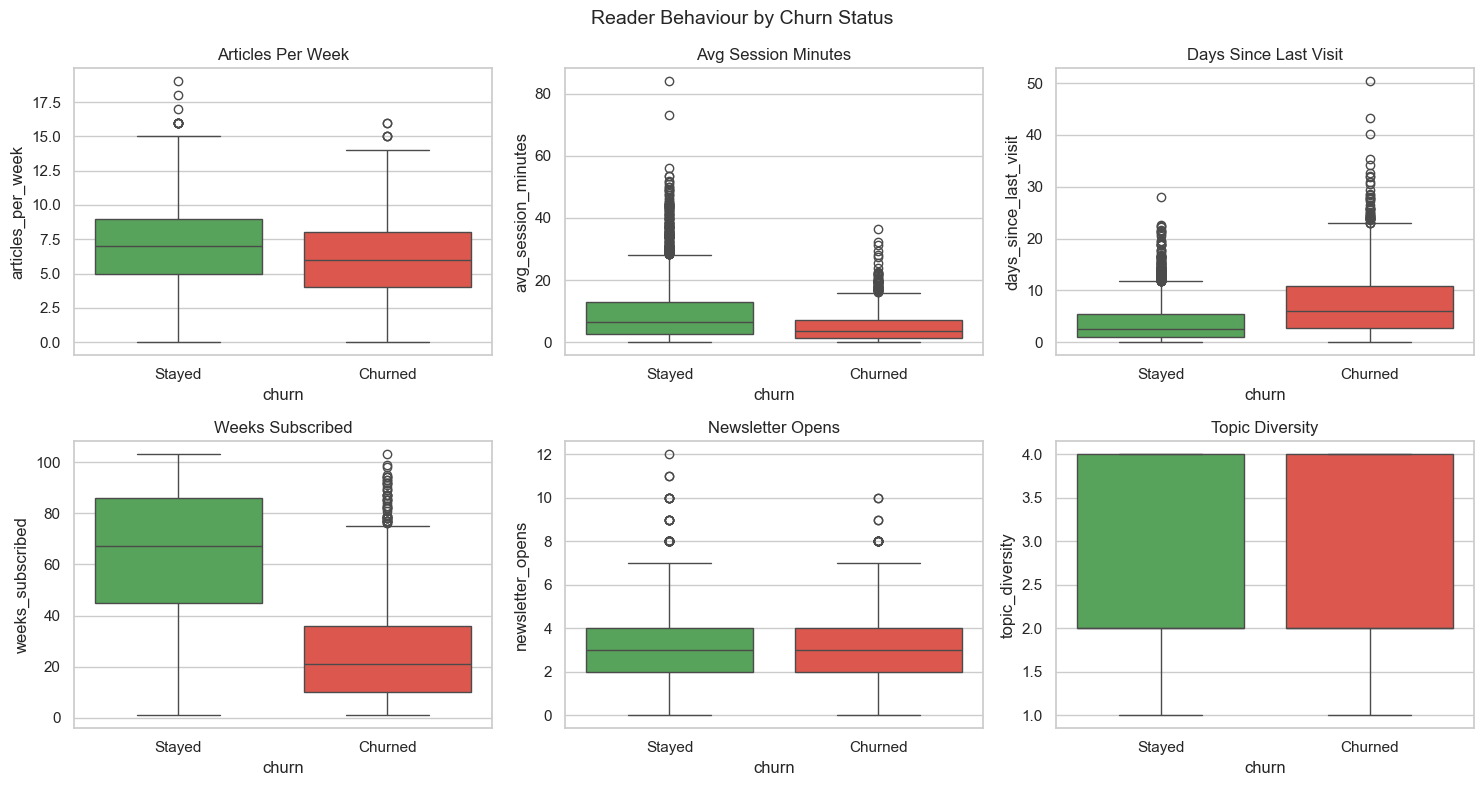

In [5]:
# Before modelling we look at how each feature relates to churn.
# This is important because it validates our simulation
# and shows which reader behaviours matter most.

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

features = [
    "articles_per_week", "avg_session_minutes",
    "days_since_last_visit", "weeks_subscribed",
    "newsletter_opens", "topic_diversity"
]

for i, feature in enumerate(features):
    sns.boxplot(
        x="churn",
        y=feature,
        data=df_readers,
        palette=["#4CAF50", "#F44336"],
        ax=axes[i]
    )
    axes[i].set_title(feature.replace("_", " ").title())
    axes[i].set_xticklabels(["Stayed", "Churned"])

plt.suptitle("Reader Behaviour by Churn Status", fontsize=14)
plt.tight_layout()
plt.savefig("../data/processed/churn_behaviour.png")
plt.show()

In [6]:
# We drop the reader ID since it is not a predictive feature.
# Then we scale numeric columns so the model treats
# all features on equal footing regardless of their range.

X = df_readers.drop(columns=["reader_id", "churn"])
y = df_readers["churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train size : {len(X_train):,}")
print(f"Test size  : {len(X_test):,}")
print(f"Features   : {X.columns.tolist()}")

Train size : 4,000
Test size  : 1,000
Features   : ['articles_per_week', 'avg_session_minutes', 'days_since_last_visit', 'weeks_subscribed', 'topic_diversity', 'newsletter_opens', 'uses_app']


In [7]:
# We train three models and track every run in MLflow.
# This way we can compare them easily and pick the best one.
# In a real production pipeline this comparison would happen
# automatically as part of a scheduled retraining job.

mlflow.set_experiment("newslens-churn-prediction")

def train_churn_model(model, model_name, params):
    with mlflow.start_run(run_name=model_name):

        mlflow.log_params(params)
        model.fit(X_train_scaled, y_train)

        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]

        accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        roc_auc = roc_auc_score(y_test, y_prob)

        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("f1_score", f1)
        mlflow.log_metric("roc_auc", roc_auc)
        mlflow.sklearn.log_model(model, artifact_path="model")

        print(f"\n{model_name}")
        print(f"  Accuracy : {accuracy:.4f}")
        print(f"  F1 Score : {f1:.4f}")
        print(f"  ROC AUC  : {roc_auc:.4f}")

        return model, y_pred, roc_auc

# Logistic Regression — simple baseline
lr_params = {"C": 1.0, "max_iter": 1000}
lr_model = LogisticRegression(**lr_params)
lr_model, lr_preds, lr_auc = train_churn_model(
    lr_model, "LogisticRegression", lr_params
)

# Random Forest — better with non-linear patterns
rf_params = {"n_estimators": 100, "max_depth": 10, "random_state": 42}
rf_model = RandomForestClassifier(**rf_params)
rf_model, rf_preds, rf_auc = train_churn_model(
    rf_model, "RandomForest", rf_params
)

# Gradient Boosting — usually best for tabular data
gb_params = {"n_estimators": 100, "max_depth": 4, "random_state": 42}
gb_model = GradientBoostingClassifier(**gb_params)
gb_model, gb_preds, gb_auc = train_churn_model(
    gb_model, "GradientBoosting", gb_params
)

2026/10/23 13:13:12 INFO mlflow.tracking.fluent: Experiment with name 'newslens-churn-prediction' does not exist. Creating a new experiment.
2026/10/23 13:13:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/23 13:13:15 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



LogisticRegression
  Accuracy : 0.9290
  F1 Score : 0.8786
  ROC AUC  : 0.9823


2026/10/23 13:13:15 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/23 13:13:17 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



RandomForest
  Accuracy : 0.9220
  F1 Score : 0.8651
  ROC AUC  : 0.9773


2026/10/23 13:13:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/23 13:13:19 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.



GradientBoosting
  Accuracy : 0.9160
  F1 Score : 0.8581
  ROC AUC  : 0.9769


Best model: LogisticRegression (ROC AUC: 0.9823)


/var/folders/d0/ymvkftpj5hzdbp0bfg1vxwvr0000gn/T/ipykernel_79948/208796153.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="importance", y="feature", data=feat_imp, palette="Blues_d")


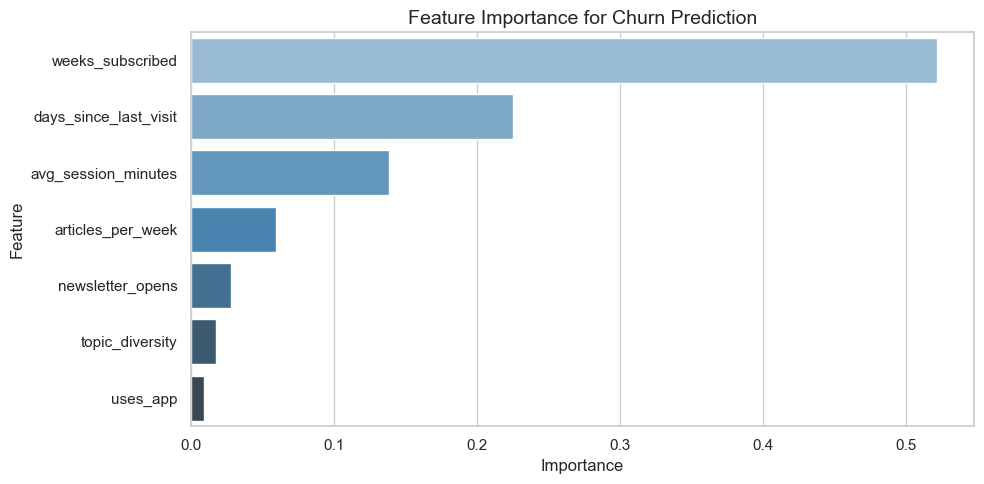

In [8]:
# Feature importance tells us which reader behaviours
# are the strongest signals for predicting churn.
# This is very actionable for a publisher — if days since
# last visit is the top feature they know to focus on
# re-engagement campaigns for lapsed readers.

best_model = max(
    [(lr_model, lr_auc, "LogisticRegression"),
     (rf_model, rf_auc, "RandomForest"),
     (gb_model, gb_auc, "GradientBoosting")],
    key=lambda x: x[1]
)

best_clf, best_auc, best_name = best_model
print(f"Best model: {best_name} (ROC AUC: {best_auc:.4f})")

# Get feature importances from the best tree-based model
importances = rf_model.feature_importances_
feature_names = X.columns.tolist()

feat_imp = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x="importance", y="feature", data=feat_imp, palette="Blues_d")
plt.title("Feature Importance for Churn Prediction", fontsize=14)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("../data/processed/churn_feature_importance.png")
plt.show()

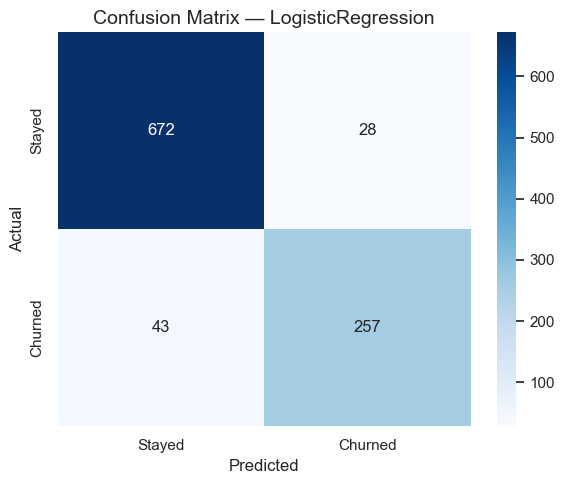

In [9]:
# The confusion matrix shows us not just overall accuracy
# but what kind of mistakes the model makes.
# For churn it is usually better to have false positives
# (we try to re-engage someone who wasn't going to leave)
# than false negatives (we miss someone who does leave).

best_preds = best_clf.predict(X_test_scaled)

cm = confusion_matrix(y_test, best_preds)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Stayed", "Churned"],
    yticklabels=["Stayed", "Churned"]
)
plt.title(f"Confusion Matrix — {best_name}", fontsize=14)
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.savefig("../data/processed/churn_confusion_matrix.png")
plt.show()

In [10]:
# The most practical output of a churn model is a list of
# readers ranked by their churn probability. A publisher
# can use this list to trigger re-engagement campaigns —
# sending a personalised email or a special offer to the
# readers most likely to leave. This is exactly what
# Upscore's Convert product does for its clients.

churn_probabilities = best_clf.predict_proba(X_test_scaled)[:, 1]

at_risk = X_test.copy()
at_risk["churn_probability"] = churn_probabilities
at_risk["reader_id"] = df_readers.loc[X_test.index, "reader_id"].values
at_risk = at_risk.sort_values("churn_probability", ascending=False)

print("Top 10 readers most at risk of churning:")
print()
display(at_risk[["reader_id", "churn_probability",
                  "days_since_last_visit",
                  "articles_per_week"]].head(10))

Top 10 readers most at risk of churning:



,reader_id,churn_probability,days_since_last_visit,articles_per_week
1293,reader_1293,1.000000,34.2,5
510,reader_510,1.000000,35.4,8
2800,reader_2800,1.000000,29.4,7
2536,reader_2536,1.000000,23.7,5
1216,reader_1216,1.000000,21.7,10
2405,reader_2405,0.999998,16.4,4
3401,reader_3401,0.999998,20.8,4
4489,reader_4489,0.999995,17.7,7
2191,reader_2191,0.999986,20.2,10
831,reader_831,0.999981,12.6,6


In [11]:
import pickle

with open("../data/processed/churn_model.pkl", "wb") as f:
    pickle.dump(best_clf, f)

with open("../data/processed/churn_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

df_readers.to_csv("../data/processed/readers.csv", index=False)

print("Saved churn model    → data/processed/churn_model.pkl")
print("Saved scaler         → data/processed/churn_scaler.pkl")
print("Saved reader profiles → data/processed/readers.csv")

Saved churn model    → data/processed/churn_model.pkl
Saved scaler         → data/processed/churn_scaler.pkl
Saved reader profiles → data/processed/readers.csv


In [12]:
# We now have a working churn model that identifies
# at-risk readers before they leave. Combined with the
# topic classifier from notebook 02 we can not only
# predict who will churn but also understand what content
# they were reading — giving publishers the full picture.

print("=== CHURN PREDICTION SUMMARY ===")
print(f"Readers modelled : {len(df_readers):,}")
print(f"Churn rate       : {df_readers['churn'].mean():.1%}")
print(f"Best model       : {best_name}")
print(f"Best ROC AUC     : {best_auc:.4f}")
print()
print("Next: build the article recommendation engine")
print("to suggest content to at-risk readers!")

=== CHURN PREDICTION SUMMARY ===
Readers modelled : 5,000
Churn rate       : 30.0%
Best model       : LogisticRegression
Best ROC AUC     : 0.9823

Next: build the article recommendation engine
to suggest content to at-risk readers!
